In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path(
        r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
    )

os.chdir(PROJECT_ROOT)

REPORT_DIR = PROJECT_ROOT / "outputs" / "reports"
CHART_DIR = PROJECT_ROOT / "outputs" / "charts"
FORECAST_DIR = PROJECT_ROOT / "data" / "forecasts"

for folder in [REPORT_DIR, CHART_DIR, FORECAST_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Notebook 12 environment ready.")

Project: C:\Users\adity\Downloads\Historical data\BharatMarket_AI
Notebook 12 environment ready.


In [2]:
FILES = {
    "return_walk_forward": (
        REPORT_DIR / "return_based_walk_forward_results.csv"
    ),
    "return_model_comparison": (
        REPORT_DIR / "return_based_model_comparison.csv"
    ),
    "return_best_models": (
        REPORT_DIR / "return_based_best_models.csv"
    ),
    "return_feature_importance": (
        REPORT_DIR / "return_based_average_feature_importance.csv"
    ),
    "return_predictions": (
        FORECAST_DIR / "return_based_walk_forward_predictions.csv"
    ),
    "forecast_summary": (
        FORECAST_DIR / "bharatmarket_return_based_forecasts.csv"
    ),
    "signal_summary": (
        REPORT_DIR / "bharatmarket_return_based_signals.csv"
    ),
    "backtest_performance": (
        REPORT_DIR / "backtest_performance_summary.csv"
    ),
    "instrument_performance": (
        REPORT_DIR / "backtest_instrument_performance.csv"
    ),
    "risk_scorecard": (
        REPORT_DIR / "risk_management_scorecard.csv"
    ),
    "ml_comparison": (
        REPORT_DIR / "machine_learning_model_comparison.csv"
    )
}

loaded = {}
missing_files = []

for name, path in FILES.items():

    if path.exists():
        loaded[name] = pd.read_csv(path)
        print(f"FOUND: {name} — {loaded[name].shape}")

    else:
        missing_files.append(name)
        print(f"NOT FOUND: {name}")

print("\nAvailable datasets:", len(loaded))
print("Missing optional datasets:", len(missing_files))

FOUND: return_walk_forward — (360, 12)
FOUND: return_model_comparison — (60, 10)
FOUND: return_best_models — (10, 10)
FOUND: return_feature_importance — (2480, 4)
FOUND: return_predictions — (10390, 10)
FOUND: forecast_summary — (10, 26)
FOUND: signal_summary — (10, 6)
FOUND: backtest_performance — (1, 16)
FOUND: instrument_performance — (3, 8)
FOUND: risk_scorecard — (1, 16)
FOUND: ml_comparison — (60, 10)

Available datasets: 11
Missing optional datasets: 0


In [3]:
for name in [
    "return_walk_forward",
    "return_model_comparison",
    "return_best_models",
    "ml_comparison",
    "backtest_performance",
    "risk_scorecard"
]:

    if name in loaded:

        print("\n" + "=" * 65)
        print(name.upper())
        print("=" * 65)

        print("Columns:", loaded[name].columns.tolist())
        display(loaded[name].head(5))


RETURN_WALK_FORWARD
Columns: ['Instrument', 'Fold', 'Model', 'Train_Size', 'Validation_Size', 'Return_MAE', 'Return_RMSE', 'Price_MAE', 'Price_RMSE', 'Price_R2', 'Directional_Accuracy', 'Directional_Coverage_Pct']


,Instrument,Fold,Model,Train_Size,Validation_Size,Return_MAE,Return_RMSE,Price_MAE,Price_RMSE,Price_R2,Directional_Accuracy,Directional_Coverage_Pct
0,NIFTY50,1,Zero Return Baseline,827,35,0.807410,0.986677,203.335658,247.642035,0.782493,NaN,0.0
1,NIFTY50,1,Linear Regression,827,35,1.065693,1.433068,267.918357,357.253018,0.547335,51.428571,100.0
2,NIFTY50,1,Decision Tree,827,35,0.858797,1.055289,216.578933,264.525810,0.751823,42.857143,100.0
3,NIFTY50,1,Random Forest,827,35,0.818389,1.022813,206.305752,256.628946,0.766420,40.000000,100.0
4,NIFTY50,1,Gradient Boosting,827,35,0.814080,1.077714,205.199485,270.210263,0.741043,57.142857,100.0



RETURN_MODEL_COMPARISON
Columns: ['Instrument', 'Model', 'Mean_Return_MAE', 'Mean_Return_RMSE', 'Mean_Price_MAE', 'Mean_Price_RMSE', 'Mean_Price_R2', 'Mean_Directional_Accuracy', 'Mean_Directional_Coverage', 'Std_Price_RMSE']


,Instrument,Model,Mean_Return_MAE,Mean_Return_RMSE,Mean_Price_MAE,Mean_Price_RMSE,Mean_Price_R2,Mean_Directional_Accuracy,Mean_Directional_Coverage,Std_Price_RMSE
0,BANKNIFTY,Decision Tree,1.045692,1.359331,592.800500,769.237779,0.165087,51.148459,100.0,244.586401
1,BANKNIFTY,Gradient Boosting,0.946209,1.239567,536.053950,701.538882,0.552529,51.162465,100.0,215.354065
2,BANKNIFTY,Linear Regression,1.079209,1.373935,612.547715,780.108066,0.474470,50.196078,100.0,133.004923
3,BANKNIFTY,Random Forest,0.936241,1.220353,529.952472,690.226942,0.621122,48.851541,100.0,226.933684
4,BANKNIFTY,XGBoost,0.916152,1.205055,519.327231,682.487285,0.651410,45.420168,100.0,225.198462



RETURN_BEST_MODELS
Columns: ['Instrument', 'Best_Model', 'Mean_Return_MAE', 'Mean_Return_RMSE', 'Mean_Price_MAE', 'Mean_Price_RMSE', 'Mean_Price_R2', 'Mean_Directional_Accuracy', 'Mean_Directional_Coverage', 'Std_Price_RMSE']


,Instrument,Best_Model,Mean_Return_MAE,Mean_Return_RMSE,Mean_Price_MAE,Mean_Price_RMSE,Mean_Price_R2,Mean_Directional_Accuracy,Mean_Directional_Coverage,Std_Price_RMSE
0,BANKNIFTY,Zero Return Baseline,0.904039,1.176572,511.130521,664.688814,0.675160,45.420168,0.0,226.332996
1,HDFCBANK,Gradient Boosting,1.215628,1.545031,9.529327,12.156736,0.722470,42.927171,100.0,3.166703
2,ICICIBANK,Zero Return Baseline,1.068465,1.366950,14.525811,18.621060,0.799852,45.658263,0.0,4.889060
3,INFY,Zero Return Baseline,1.568403,2.084895,18.585570,24.959613,0.823525,46.120448,0.0,3.849441
4,ITC,Linear Regression,1.031992,1.360808,2.981302,3.917680,0.648470,53.375350,100.0,0.786501


... (2 outputs left out)


BACKTEST_PERFORMANCE
Columns: ['Initial_Capital', 'Final_Capital', 'Net_Profit', 'Total_Return_Pct', 'Total_Trades', 'Winning_Trades', 'Losing_Trades', 'Win_Rate_Pct', 'Gross_Profit', 'Gross_Loss', 'Profit_Factor', 'Average_Trade_PnL', 'Best_Trade', 'Worst_Trade', 'Maximum_Drawdown_Pct', 'Sharpe_Ratio']


,Initial_Capital,Final_Capital,Net_Profit,Total_Return_Pct,Total_Trades,Winning_Trades,Losing_Trades,Win_Rate_Pct,Gross_Profit,Gross_Loss,Profit_Factor,Average_Trade_PnL,Best_Trade,Worst_Trade,Maximum_Drawdown_Pct,Sharpe_Ratio
0,100000,103876.62367,3876.62367,3.876624,94,47,47,50.0,15233.900792,11357.277123,1.341334,41.240677,1403.780844,-1013.414302,-2.412466,1.143404



RISK_SCORECARD
Columns: ['Initial_Capital', 'Final_Capital', 'Net_Profit', 'Total_Return_Pct', 'Total_Trades', 'Win_Rate_Pct', 'Annualized_Return_Pct', 'Annualized_Volatility_Pct', 'Sharpe_Ratio', 'Sortino_Ratio', 'Maximum_Drawdown_Pct', 'Maximum_Consecutive_Losses', 'Daily_Loss_Breaches', 'Risk_Budget_Exceeded_Trades', 'Historical_VaR_95_Pct', 'Historical_CVaR_95_Pct']


,Initial_Capital,Final_Capital,Net_Profit,Total_Return_Pct,Total_Trades,Win_Rate_Pct,Annualized_Return_Pct,Annualized_Volatility_Pct,Sharpe_Ratio,Sortino_Ratio,Maximum_Drawdown_Pct,Maximum_Consecutive_Losses,Daily_Loss_Breaches,Risk_Budget_Exceeded_Trades,Historical_VaR_95_Pct,Historical_CVaR_95_Pct
0,100000.0,103876.62367,3876.62367,3.876624,94,50.0,4.715743,4.103496,1.143404,1.962091,-2.412466,4,0,1,-0.295289,-0.54713


In [4]:
required_columns = [
    "Instrument",
    "Fold",
    "Date",
    "Model",
    "Current_Close",
    "Actual_Next_Return_Pct",
    "Predicted_Next_Return_Pct",
    "Actual_Next_Close",
    "Predicted_Next_Close"
]

if "return_predictions" not in loaded:
    raise FileNotFoundError(
        "Missing return_based_walk_forward_predictions.csv"
    )

predictions = loaded["return_predictions"].copy()

missing = [
    col for col in required_columns
    if col not in predictions.columns
]

if missing:
    raise ValueError(
        f"Missing columns in walk-forward predictions: {missing}"
    )

predictions["Date"] = pd.to_datetime(
    predictions["Date"], errors="coerce"
)

numeric_columns = [
    "Current_Close",
    "Actual_Next_Return_Pct",
    "Predicted_Next_Return_Pct",
    "Actual_Next_Close",
    "Predicted_Next_Close"
]

for col in numeric_columns:
    predictions[col] = pd.to_numeric(
        predictions[col], errors="coerce"
    )

predictions["Instrument"] = (
    predictions["Instrument"].astype(str).str.upper().str.strip()
)

predictions["Model"] = (
    predictions["Model"].astype(str).str.strip()
)

predictions = predictions.dropna(
    subset=[
        "Instrument", "Date",
        "Actual_Next_Return_Pct",
        "Predicted_Next_Return_Pct"
    ]
)

# Remove duplicated model/date observations if any.
predictions = predictions.drop_duplicates(
    subset=["Instrument", "Fold", "Date", "Model"]
)

print("Valid out-of-sample prediction records:", len(predictions))
print("Instruments:", predictions["Instrument"].nunique())
print("Models:", sorted(predictions["Model"].unique()))

display(predictions.head())

Valid out-of-sample prediction records: 10390
Instruments: 10
Models: ['Decision Tree', 'Gradient Boosting', 'Linear Regression', 'Random Forest', 'XGBoost']


,Instrument,Fold,Date,Model,Current_Close,Actual_Next_Return_Pct,Predicted_Next_Return_Pct,Actual_Next_Close,Predicted_Next_Close,Prediction_Error
0,NIFTY50,1,2026-01-19,Linear Regression,25585.500000,-1.379688,-0.287026,25232.500000,25512.062951,-279.562951
1,NIFTY50,1,2026-01-20,Linear Regression,25232.500000,-0.297236,0.296214,25157.500000,25307.242299,-149.742299
2,NIFTY50,1,2026-01-21,Linear Regression,25157.500000,0.526286,0.313782,25289.900391,25236.439626,53.460764
3,NIFTY50,1,2026-01-22,Linear Regression,25289.900391,-0.953938,0.012699,25048.650391,25293.111913,-244.461522
4,NIFTY50,1,2026-01-23,Linear Regression,25048.650391,0.506015,0.505831,25175.400391,25175.354199,0.046191


In [5]:
baseline_source = predictions[
    [
        "Instrument",
        "Fold",
        "Date",
        "Current_Close",
        "Actual_Next_Return_Pct",
        "Actual_Next_Close"
    ]
].drop_duplicates(
    subset=["Instrument", "Fold", "Date"]
).copy()

baseline_source["Model"] = "Zero Return Baseline"
baseline_source["Predicted_Next_Return_Pct"] = 0.0

baseline_source["Predicted_Next_Close"] = (
    baseline_source["Current_Close"]
)

baseline_source["Prediction_Error"] = (
    baseline_source["Actual_Next_Return_Pct"]
)

baseline_source["Price_Prediction_Error"] = (
    baseline_source["Actual_Next_Close"] -
    baseline_source["Predicted_Next_Close"]
)

# Combine all machine-learning predictions with the baseline.
comparison_predictions = pd.concat(
    [
        predictions[
            [
                "Instrument", "Fold", "Date", "Model",
                "Current_Close",
                "Actual_Next_Return_Pct",
                "Predicted_Next_Return_Pct",
                "Actual_Next_Close",
                "Predicted_Next_Close"
            ]
        ],
        baseline_source[
            [
                "Instrument", "Fold", "Date", "Model",
                "Current_Close",
                "Actual_Next_Return_Pct",
                "Predicted_Next_Return_Pct",
                "Actual_Next_Close",
                "Predicted_Next_Close"
            ]
        ]
    ],
    ignore_index=True
)

comparison_predictions = comparison_predictions.drop_duplicates(
    subset=["Instrument", "Fold", "Date", "Model"]
)

comparison_predictions["Return_Error"] = (
    comparison_predictions["Actual_Next_Return_Pct"] -
    comparison_predictions["Predicted_Next_Return_Pct"]
)

comparison_predictions["Price_Error"] = (
    comparison_predictions["Actual_Next_Close"] -
    comparison_predictions["Predicted_Next_Close"]
)

print("Combined model observations:", len(comparison_predictions))
print("Models including baseline:")
print(sorted(comparison_predictions["Model"].unique()))

Combined model observations: 12468
Models including baseline:
['Decision Tree', 'Gradient Boosting', 'Linear Regression', 'Random Forest', 'XGBoost', 'Zero Return Baseline']


In [6]:
def calculate_model_metrics(group):

    actual = group["Actual_Next_Return_Pct"].to_numpy(dtype=float)
    predicted = group["Predicted_Next_Return_Pct"].to_numpy(dtype=float)

    actual_price = group["Actual_Next_Close"].to_numpy(dtype=float)
    predicted_price = group["Predicted_Next_Close"].to_numpy(dtype=float)

    valid = (
        np.isfinite(actual) &
        np.isfinite(predicted)
    )

    actual = actual[valid]
    predicted = predicted[valid]

    actual_price = actual_price[valid]
    predicted_price = predicted_price[valid]

    if len(actual) == 0:
        return pd.Series(dtype=float)

    error = actual - predicted

    actual_direction = np.sign(actual)
    predicted_direction = np.sign(predicted)

    covered = predicted != 0

    directional_accuracy_all = (
        np.mean(actual_direction == predicted_direction) * 100
    )

    directional_accuracy_covered = (
        np.mean(
            actual_direction[covered] ==
            predicted_direction[covered]
        ) * 100
        if covered.any() else np.nan
    )

    price_valid = (
        np.isfinite(actual_price) &
        np.isfinite(predicted_price)
    )

    price_error = (
        actual_price[price_valid] -
        predicted_price[price_valid]
    )

    return pd.Series({
        "Observations": len(actual),

        "Return_MAE": np.mean(np.abs(error)),
        "Return_RMSE": np.sqrt(np.mean(error ** 2)),

        "Price_MAE": (
            np.mean(np.abs(price_error))
            if len(price_error) else np.nan
        ),

        "Price_RMSE": (
            np.sqrt(np.mean(price_error ** 2))
            if len(price_error) else np.nan
        ),

        "Directional_Accuracy_All_Pct": directional_accuracy_all,
        "Directional_Accuracy_Covered_Pct": directional_accuracy_covered,

        "Directional_Coverage_Pct": (
            covered.mean() * 100
        )
    })


instrument_model_metrics = (
    comparison_predictions
    .groupby(["Instrument", "Model"])
    .apply(calculate_model_metrics, include_groups=False)
    .reset_index()
)

print("Instrument-level model comparison:")
display(instrument_model_metrics.head(20))

Instrument-level model comparison:


,Instrument,Model,Observations,Return_MAE,Return_RMSE,Price_MAE,Price_RMSE,Directional_Accuracy_All_Pct,Directional_Accuracy_Covered_Pct,Directional_Coverage_Pct
0,BANKNIFTY,Decision Tree,207.0,1.046014,1.422810,592.852427,801.434048,51.207729,51.207729,100.0
1,BANKNIFTY,Gradient Boosting,207.0,0.947895,1.297309,536.892762,729.824491,51.207729,51.207729,100.0
2,BANKNIFTY,Linear Regression,207.0,1.080767,1.396724,613.303771,790.369213,50.241546,50.241546,100.0
3,BANKNIFTY,Random Forest,207.0,0.938667,1.285658,531.212847,722.226954,48.792271,48.792271,100.0
4,BANKNIFTY,XGBoost,207.0,0.918560,1.268478,520.584693,714.279697,45.410628,45.410628,100.0
5,BANKNIFTY,Zero Return Baseline,207.0,0.906356,1.244205,512.323068,697.653949,0.000000,NaN,0.0
6,HDFCBANK,Decision Tree,208.0,1.248072,1.620321,9.785328,12.731000,49.038462,49.038462,100.0
7,HDFCBANK,Gradient Boosting,208.0,1.216172,1.590323,9.539129,12.511046,42.788462,42.788462,100.0
8,HDFCBANK,Linear Regression,208.0,1.304294,1.672541,10.285355,13.333382,44.711538,44.711538,100.0
9,HDFCBANK,Random Forest,208.0,1.239849,1.609259,9.709307,12.635308,45.192308,45.192308,100.0


In [7]:
instrument_model_metrics["RMSE_Rank"] = (
    instrument_model_metrics
    .groupby("Instrument")["Return_RMSE"]
    .rank(method="min", ascending=True)
)

instrument_model_metrics["MAE_Rank"] = (
    instrument_model_metrics
    .groupby("Instrument")["Return_MAE"]
    .rank(method="min", ascending=True)
)

best_model_per_instrument = (
    instrument_model_metrics
    .sort_values(
        ["Instrument", "Return_RMSE", "Return_MAE"],
        ascending=[True, True, True]
    )
    .groupby("Instrument")
    .head(1)
    .reset_index(drop=True)
)

best_model_per_instrument = best_model_per_instrument.sort_values(
    "Instrument"
)

print("Best model selected by out-of-sample return RMSE:")
display(best_model_per_instrument)

Best model selected by out-of-sample return RMSE:


,Instrument,Model,Observations,Return_MAE,Return_RMSE,Price_MAE,Price_RMSE,Directional_Accuracy_All_Pct,Directional_Accuracy_Covered_Pct,Directional_Coverage_Pct,RMSE_Rank,MAE_Rank
0,BANKNIFTY,Zero Return Baseline,207.0,0.906356,1.244205,512.323068,697.653949,0.000000,NaN,0.0,1.0,1.0
1,HDFCBANK,Gradient Boosting,208.0,1.216172,1.590323,9.539129,12.511046,42.788462,42.788462,100.0,1.0,1.0
2,ICICIBANK,Zero Return Baseline,208.0,1.068686,1.403294,14.522595,19.130837,0.000000,NaN,0.0,1.0,1.0
3,INFY,Zero Return Baseline,208.0,1.568551,2.094845,18.599996,25.238324,0.000000,NaN,0.0,1.0,1.0
4,ITC,Linear Regression,208.0,1.030638,1.381078,2.979777,3.980522,53.365385,53.365385,100.0,1.0,1.0
5,LT,Zero Return Baseline,208.0,1.214345,1.728996,47.333156,66.619954,0.000000,NaN,0.0,1.0,1.0
6,NIFTY50,Zero Return Baseline,207.0,0.743182,0.973392,177.903146,232.165886,0.000000,NaN,0.0,1.0,2.0
7,RELIANCE,Gradient Boosting,208.0,1.140734,1.586508,15.071764,20.611870,50.000000,50.000000,100.0,1.0,3.0
8,SBIN,Gradient Boosting,208.0,1.257931,1.648608,13.205800,17.440835,49.519231,49.519231,100.0,1.0,4.0
9,TCS,Zero Return Baseline,208.0,1.459702,2.024923,35.138945,49.346365,0.000000,NaN,0.0,1.0,1.0


In [8]:
overall_model_metrics = (
    instrument_model_metrics
    .groupby("Model")
    .agg(
        Instruments=("Instrument", "nunique"),
        Average_Observations=("Observations", "mean"),
        Average_Return_MAE=("Return_MAE", "mean"),
        Average_Return_RMSE=("Return_RMSE", "mean"),
        Average_Price_MAE=("Price_MAE", "mean"),
        Average_Price_RMSE=("Price_RMSE", "mean"),
        Average_Directional_Accuracy_All=(
            "Directional_Accuracy_All_Pct", "mean"
        ),
        Average_Directional_Accuracy_Covered=(
            "Directional_Accuracy_Covered_Pct", "mean"
        ),
        Average_Directional_Coverage=(
            "Directional_Coverage_Pct", "mean"
        )
    )
    .reset_index()
    .sort_values("Average_Return_RMSE")
)

overall_model_metrics["Return_RMSE_Rank"] = (
    overall_model_metrics["Average_Return_RMSE"]
    .rank(method="min")
)

display(overall_model_metrics)

,Model,Instruments,Average_Observations,Average_Return_MAE,Average_Return_RMSE,Average_Price_MAE,Average_Price_RMSE,Average_Directional_Accuracy_All,Average_Directional_Accuracy_Covered,Average_Directional_Coverage,Return_RMSE_Rank
5,Zero Return Baseline,10,207.8,1.156239,1.572990,84.590720,114.474229,0.240385,NaN,0.0,1.0
3,Random Forest,10,207.8,1.185475,1.603245,87.298790,118.674362,49.132061,49.132061,100.0,2.0
1,Gradient Boosting,10,207.8,1.190557,1.609948,87.748789,119.458488,49.229840,49.229840,100.0,3.0
4,XGBoost,10,207.8,1.195170,1.619560,86.330917,118.261972,50.334448,50.334448,100.0,4.0
0,Decision Tree,10,207.8,1.311008,1.745580,97.234684,131.123681,51.201459,51.201459,100.0,5.0
2,Linear Regression,10,207.8,1.297493,1.751072,99.324741,131.229908,50.818004,50.818004,100.0,6.0


In [9]:
if "return_best_models" in loaded:

    saved_best = loaded["return_best_models"].copy()

    saved_instrument_col = next(
        (
            c for c in saved_best.columns
            if c.lower().replace(" ", "_") in ["instrument", "symbol"]
        ),
        None
    )

    saved_model_col = next(
        (
            c for c in saved_best.columns
            if c.lower().replace(" ", "_") in [
                "best_model", "selected_model", "model"
            ]
        ),
        None
    )

    if saved_instrument_col and saved_model_col:

        saved_best = saved_best.rename(columns={
            saved_instrument_col: "Instrument",
            saved_model_col: "Saved_Best_Model"
        })

        saved_best["Instrument"] = (
            saved_best["Instrument"].astype(str).str.upper().str.strip()
        )

        ranking_comparison = best_model_per_instrument[
            ["Instrument", "Model", "Return_RMSE"]
        ].merge(
            saved_best[["Instrument", "Saved_Best_Model"]],
            on="Instrument",
            how="left"
        )

        ranking_comparison["Model_Agreement"] = (
            ranking_comparison["Model"].astype(str).str.strip() ==
            ranking_comparison["Saved_Best_Model"].astype(str).str.strip()
        )

        display(ranking_comparison)

    else:
        print("Saved best-model table has an unexpected column structure.")

else:
    print("Saved best-model summary not available.")

,Instrument,Model,Return_RMSE,Saved_Best_Model,Model_Agreement
0,BANKNIFTY,Zero Return Baseline,1.244205,Zero Return Baseline,True
1,HDFCBANK,Gradient Boosting,1.590323,Gradient Boosting,True
2,ICICIBANK,Zero Return Baseline,1.403294,Zero Return Baseline,True
3,INFY,Zero Return Baseline,2.094845,Zero Return Baseline,True
4,ITC,Linear Regression,1.381078,Linear Regression,True
5,LT,Zero Return Baseline,1.728996,Zero Return Baseline,True
6,NIFTY50,Zero Return Baseline,0.973392,Zero Return Baseline,True
7,RELIANCE,Gradient Boosting,1.586508,Gradient Boosting,True
8,SBIN,Gradient Boosting,1.648608,Zero Return Baseline,False
9,TCS,Zero Return Baseline,2.024923,Zero Return Baseline,True


In [10]:
fold_metrics = (
    comparison_predictions
    .groupby(["Instrument", "Model", "Fold"])
    .apply(calculate_model_metrics, include_groups=False)
    .reset_index()
)

fold_stability = (
    fold_metrics
    .groupby("Model")
    .agg(
        Instruments=("Instrument", "nunique"),
        Folds=("Fold", "nunique"),
        Mean_Return_RMSE=("Return_RMSE", "mean"),
        Std_Return_RMSE=("Return_RMSE", "std"),
        Mean_Return_MAE=("Return_MAE", "mean"),
        Std_Return_MAE=("Return_MAE", "std"),
        Mean_Directional_Accuracy=(
            "Directional_Accuracy_Covered_Pct", "mean"
        )
    )
    .reset_index()
    .sort_values("Mean_Return_RMSE")
)

display(fold_stability)

,Model,Instruments,Folds,Mean_Return_RMSE,Std_Return_RMSE,Mean_Return_MAE,Std_Return_MAE,Mean_Directional_Accuracy
5,Zero Return Baseline,10,6,1.527612,0.494875,1.155552,0.352083,NaN
3,Random Forest,10,6,1.556822,0.500798,1.184647,0.366544,49.148459
1,Gradient Boosting,10,6,1.563085,0.509067,1.189767,0.373097,49.231092
4,XGBoost,10,6,1.567912,0.532751,1.194310,0.401540,50.331933
0,Decision Tree,10,6,1.689485,0.568895,1.309837,0.442556,51.197479
2,Linear Regression,10,6,1.692181,0.573733,1.296101,0.433739,50.813725


In [11]:
trade_performance = None
risk_performance = None

if "backtest_performance" in loaded:

    trade_performance = loaded["backtest_performance"].copy()

    print("Notebook 10 portfolio performance:")
    display(trade_performance.T)

if "instrument_performance" in loaded:

    print("Instrument-level trading performance:")
    display(loaded["instrument_performance"])

if "risk_scorecard" in loaded:

    risk_performance = loaded["risk_scorecard"].copy()

    print("Notebook 11 risk scorecard:")
    display(risk_performance.T)

Notebook 10 portfolio performance:


,0
Initial_Capital,100000.000000
Final_Capital,103876.623670
Net_Profit,3876.623670
Total_Return_Pct,3.876624
Total_Trades,94.000000
Winning_Trades,47.000000
Losing_Trades,47.000000
Win_Rate_Pct,50.000000
Gross_Profit,15233.900792
Gross_Loss,11357.277123


Instrument-level trading performance:


,Instrument,Trades,Net_Profit,Average_Trade,Gross_Profit,Gross_Loss,Win_Rate_Pct,Profit_Factor
0,RELIANCE,42,3239.656145,77.134670,8431.516902,5191.860757,54.761905,1.623987
1,ITC,37,601.864666,16.266613,4866.426566,4264.561900,45.945946,1.141132
2,HDFCBANK,15,35.102859,2.340191,1935.957324,1900.854465,46.666667,1.018467


Notebook 11 risk scorecard:


,0
Initial_Capital,100000.000000
Final_Capital,103876.623670
Net_Profit,3876.623670
Total_Return_Pct,3.876624
Total_Trades,94.000000
Win_Rate_Pct,50.000000
Annualized_Return_Pct,4.715743
Annualized_Volatility_Pct,4.103496
Sharpe_Ratio,1.143404
Sortino_Ratio,1.962091


In [12]:
if "forecast_summary" in loaded:

    print("Latest forecast summary:")
    display(loaded["forecast_summary"].head(15))

if "signal_summary" in loaded:

    signal_data = loaded["signal_summary"].copy()

    print("Latest signal report:")
    display(signal_data.head(15))

    signal_col = next(
        (
            c for c in signal_data.columns
            if c.lower().replace(" ", "_") in ["signal", "trading_signal"]
        ),
        None
    )

    if signal_col:

        signal_distribution = (
            signal_data[signal_col]
            .value_counts()
            .rename_axis("Signal")
            .reset_index(name="Count")
        )

        display(signal_distribution)

else:
    print("Latest signal report is not available.")

Latest forecast summary:


,Instrument,Model,Last_Data_Date,Estimated_Next_Session,Current_Close,Predicted_Next_Return_Pct,Predicted_Next_Close,Expected_Change,Expected_Change_Percent,Forecast_Status,...,ATR_14,ATR_Source,Stop_Loss,Target_1,Target_2,Target_3,Risk_Per_Unit,Target_1_RR,Target_2_RR,Target_3_RR
0,NIFTY50,Zero Return Baseline,2026-11-23,2026-11-24,25349.650391,0.000000,25349.650391,0.000000,0.000000,Success,...,347.646592,ATR(14),NaN,NaN,NaN,NaN,NaN,1.0,2.0,3.0
1,BANKNIFTY,Zero Return Baseline,2026-11-23,2026-11-24,62585.351562,0.000000,62585.351562,0.000000,0.000000,Success,...,1089.233792,ATR(14),NaN,NaN,NaN,NaN,NaN,1.0,2.0,3.0
2,RELIANCE,Gradient Boosting,2026-11-23,2026-11-24,1351.000000,0.187375,1353.531436,2.531436,0.187375,Success,...,29.684408,ATR(14),NaN,NaN,NaN,NaN,NaN,1.0,2.0,3.0
3,TCS,Zero Return Baseline,2026-11-23,2026-11-24,2460.000000,0.000000,2460.000000,0.000000,0.000000,Success,...,69.968278,ATR(14),NaN,NaN,NaN,NaN,NaN,1.0,2.0,3.0
4,HDFCBANK,Gradient Boosting,2026-11-23,2026-11-24,817.799988,-0.291074,815.419585,-2.380403,-0.291074,Success,...,19.729037,ATR(14),NaN,NaN,NaN,NaN,NaN,1.0,2.0,3.0
5,INFY,Zero Return Baseline,2026-11-23,2026-11-24,1103.400024,0.000000,1103.400024,0.000000,0.000000,Success,...,34.285440,ATR(14),NaN,NaN,NaN,NaN,NaN,1.0,2.0,3.0
6,ICICIBANK,Zero Return Baseline,2026-11-23,2026-11-24,1585.500000,0.000000,1585.500000,0.000000,0.000000,Success,...,33.073498,ATR(14),NaN,NaN,NaN,NaN,NaN,1.0,2.0,3.0
7,SBIN,Zero Return Baseline,2026-11-23,2026-11-24,1132.650024,0.000000,1132.650024,0.000000,0.000000,Success,...,26.594652,ATR(14),NaN,NaN,NaN,NaN,NaN,1.0,2.0,3.0
8,ITC,Linear Regression,2026-11-23,2026-11-24,301.000000,-0.237212,300.285992,-0.714008,-0.237212,Success,...,6.577940,ATR(14),NaN,NaN,NaN,NaN,NaN,1.0,2.0,3.0
9,LT,Zero Return Baseline,2026-11-23,2026-11-24,4099.899902,0.000000,4099.899902,0.000000,0.000000,Success,...,83.862739,ATR(14),NaN,NaN,NaN,NaN,NaN,1.0,2.0,3.0


Latest signal report:


,Instrument,Signal,RSI_14,MACD,MACD_Signal,Signal_Reason
0,NIFTY50,HOLD,66.986059,649.303766,565.925659,Forecast movement is below the signal threshol...
1,BANKNIFTY,HOLD,67.708396,2063.962792,1561.537568,Forecast movement is below the signal threshol...
2,RELIANCE,HOLD,64.888829,39.365804,34.045126,Forecast movement is below the signal threshol...
3,TCS,HOLD,57.150142,15.539041,32.225377,Forecast movement is below the signal threshol...
4,HDFCBANK,HOLD,65.190952,30.638457,24.811531,MACD bearish confirmation is absent.
5,INFY,HOLD,45.386176,0.668282,10.773014,Forecast movement is below the signal threshol...
6,ICICIBANK,HOLD,65.342783,60.902883,54.626167,Forecast movement is below the signal threshol...
7,SBIN,HOLD,70.279529,45.292410,31.980583,Forecast movement is below the signal threshol...
8,ITC,HOLD,73.015191,9.189864,7.005816,Forecast movement is below the signal threshol...
9,LT,HOLD,59.081114,102.224788,96.340299,Forecast movement is below the signal threshol...


,Signal,Count
0,HOLD,10


Feature importance columns:
['Instrument', 'Model', 'Feature', 'Importance']


,Instrument,Model,Feature,Importance
0,BANKNIFTY,Decision Tree,adj_close,0.000000
1,BANKNIFTY,Decision Tree,atr_14,0.016356
2,BANKNIFTY,Decision Tree,atr_percentage,0.000000
3,BANKNIFTY,Decision Tree,bb_lower,0.000000
4,BANKNIFTY,Decision Tree,bb_middle,0.000000
5,BANKNIFTY,Decision Tree,bb_position,0.005097
6,BANKNIFTY,Decision Tree,bb_upper,0.000000
7,BANKNIFTY,Decision Tree,bb_width,0.012769
8,BANKNIFTY,Decision Tree,candle_body,0.000000
9,BANKNIFTY,Decision Tree,candle_body_percentage,0.000000


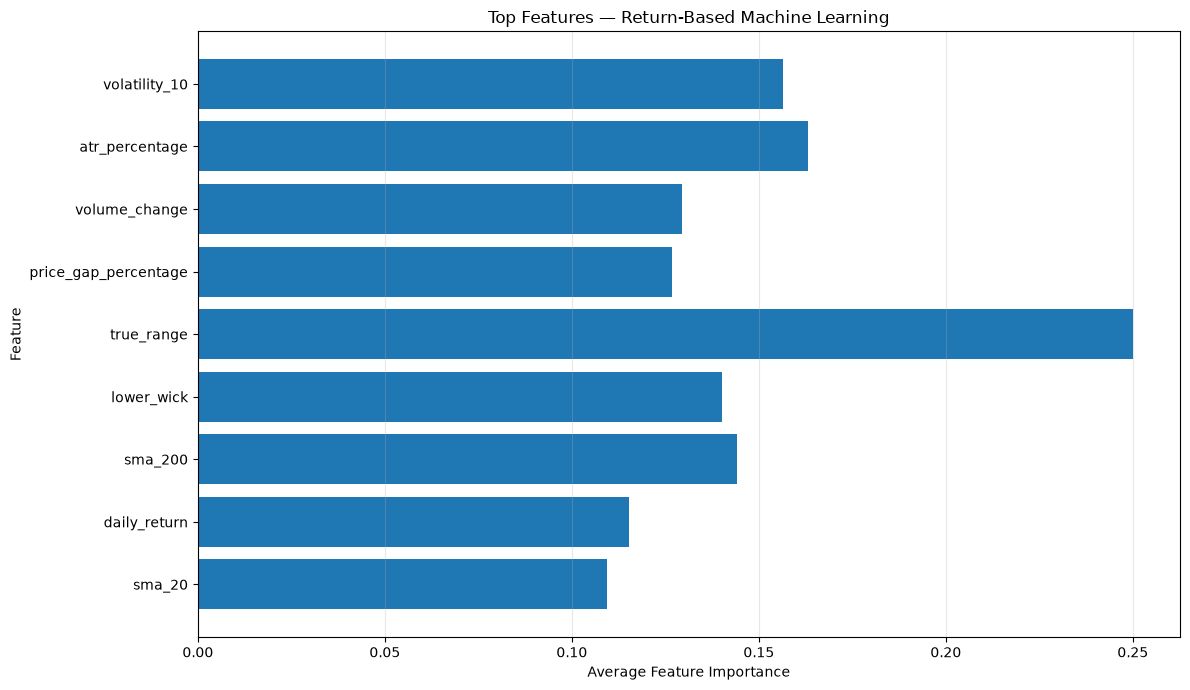

In [13]:
if "return_feature_importance" in loaded:

    feature_importance = loaded["return_feature_importance"].copy()

    print("Feature importance columns:")
    print(feature_importance.columns.tolist())

    display(feature_importance.head(20))

    feature_col = next(
        (
            c for c in feature_importance.columns
            if c.lower().replace(" ", "_") in [
                "feature", "feature_name"
            ]
        ),
        None
    )

    importance_col = next(
        (
            c for c in feature_importance.columns
            if c.lower().replace(" ", "_") in [
                "importance", "average_importance",
                "mean_importance", "importance_mean"
            ]
        ),
        None
    )

    if feature_col and importance_col:

        feature_importance[importance_col] = pd.to_numeric(
            feature_importance[importance_col],
            errors="coerce"
        )

        top_features = (
            feature_importance
            .dropna(subset=[importance_col])
            .sort_values(importance_col, ascending=False)
            .head(15)
        )

        plt.figure(figsize=(12, 7))

        plt.barh(
            top_features[feature_col].astype(str)[::-1],
            top_features[importance_col][::-1]
        )

        plt.title("Top Features — Return-Based Machine Learning")
        plt.xlabel("Average Feature Importance")
        plt.ylabel("Feature")
        plt.grid(axis="x", alpha=0.3)
        plt.tight_layout()

        plt.savefig(
            CHART_DIR / "model_feature_importance_comparison.png",
            dpi=150,
            bbox_inches="tight"
        )

        plt.show()

    else:
        print(
            "Could not identify feature and importance columns. "
            "Inspect the displayed report before plotting."
        )

else:
    print("Feature importance report not available.")

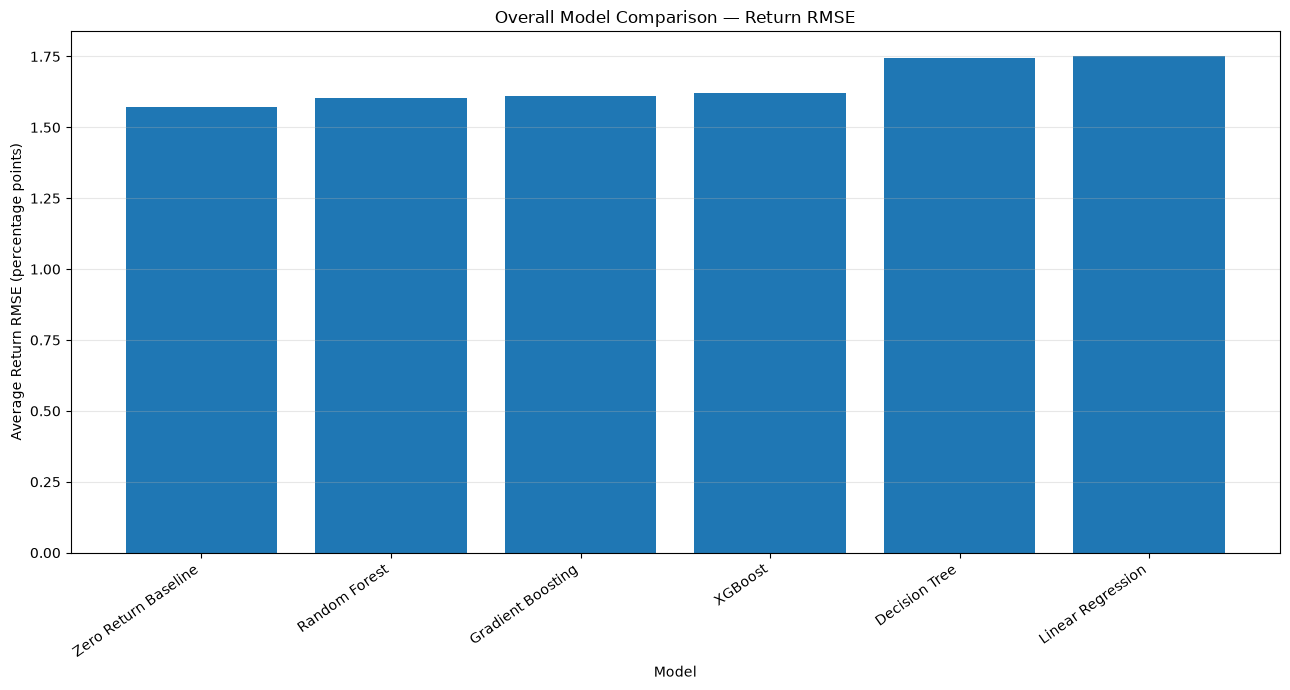

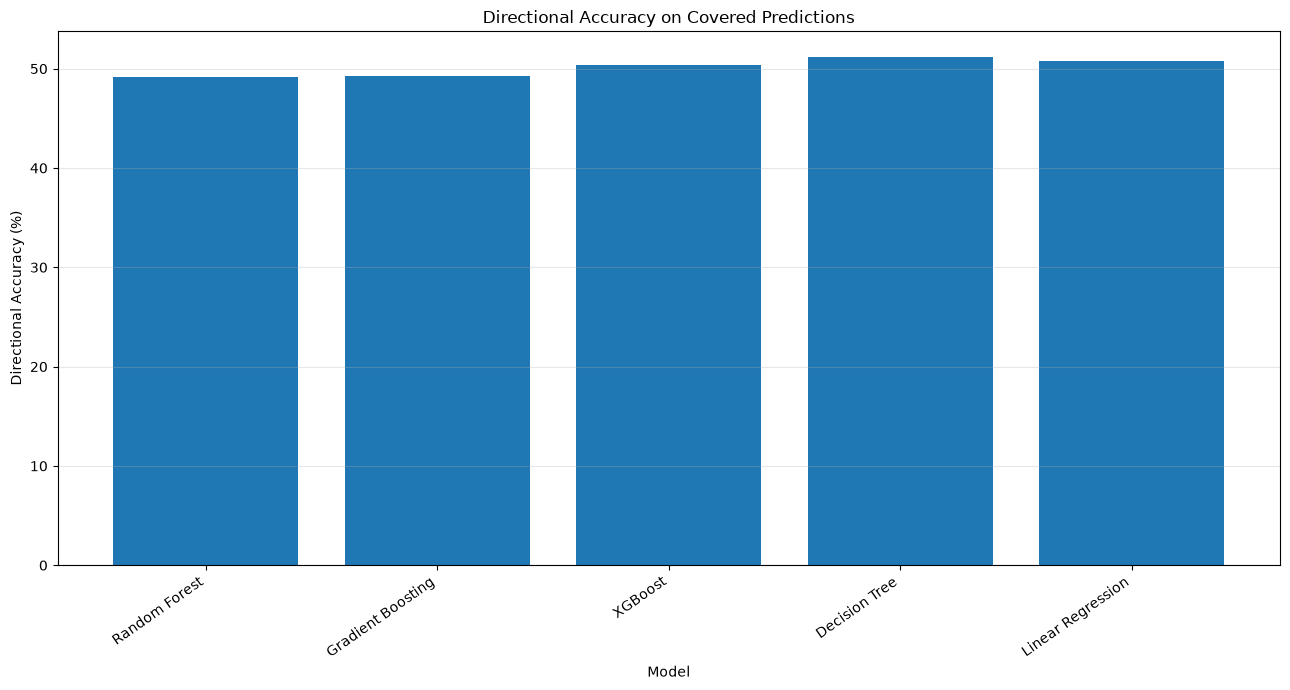

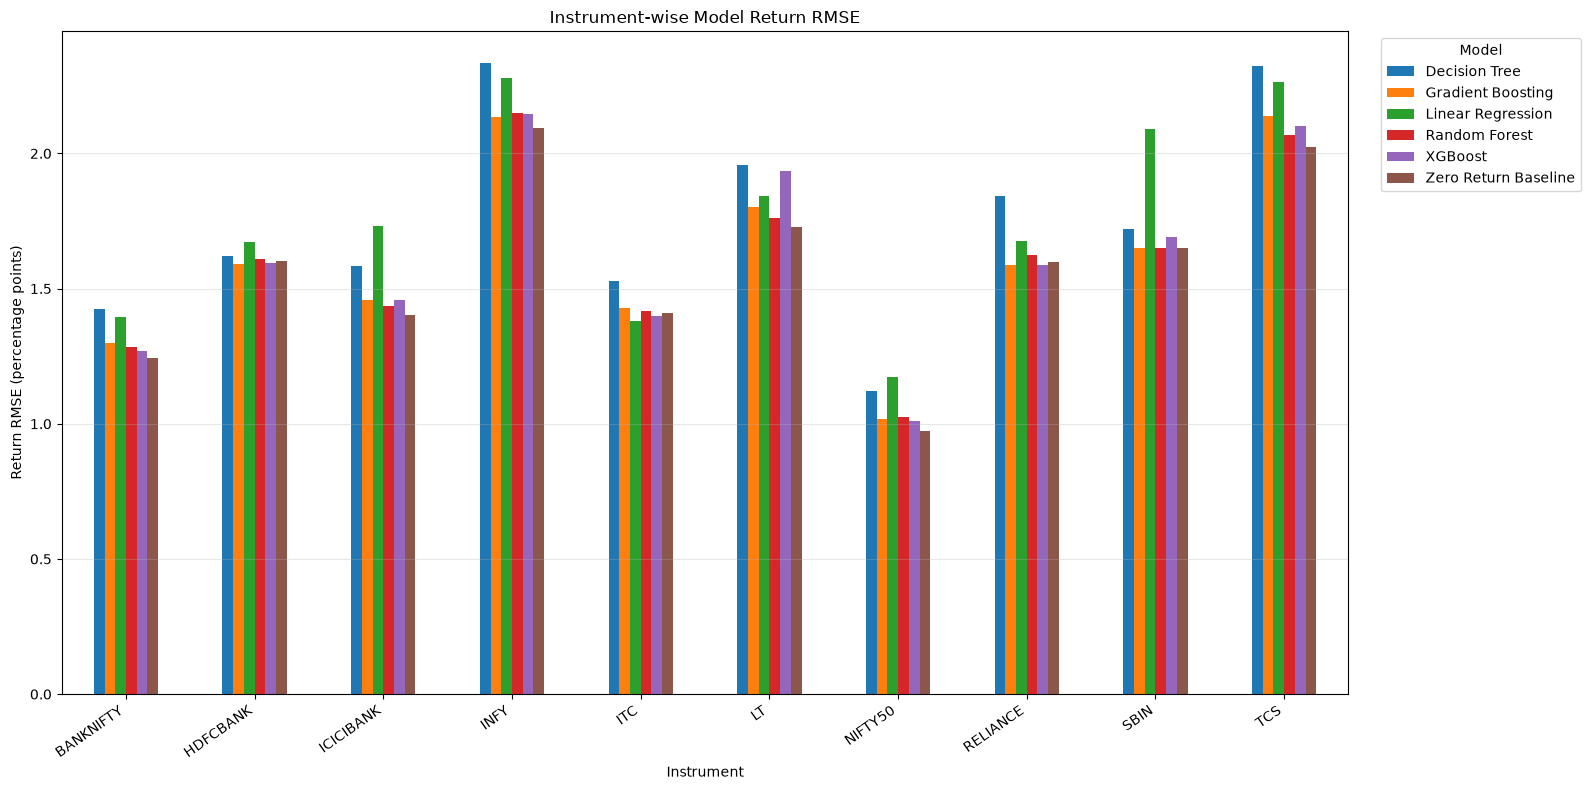

In [14]:
# Return RMSE comparison
plt.figure(figsize=(13, 7))

plt.bar(
    overall_model_metrics["Model"],
    overall_model_metrics["Average_Return_RMSE"]
)

plt.title("Overall Model Comparison — Return RMSE")
plt.ylabel("Average Return RMSE (percentage points)")
plt.xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "overall_model_return_rmse.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# Directional accuracy comparison
plt.figure(figsize=(13, 7))

plt.bar(
    overall_model_metrics["Model"],
    overall_model_metrics["Average_Directional_Accuracy_Covered"]
)

plt.title("Directional Accuracy on Covered Predictions")
plt.ylabel("Directional Accuracy (%)")
plt.xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "overall_model_directional_accuracy.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# Instrument-wise RMSE comparison
pivot_rmse = instrument_model_metrics.pivot(
    index="Instrument",
    columns="Model",
    values="Return_RMSE"
)

pivot_rmse.plot(
    kind="bar",
    figsize=(16, 8)
)

plt.title("Instrument-wise Model Return RMSE")
plt.ylabel("Return RMSE (percentage points)")
plt.xlabel("Instrument")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "instrument_wise_model_rmse.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [15]:
# Determine the overall lowest-RMSE model.
overall_best_model = overall_model_metrics.iloc[0]["Model"]

# Count instrument-level winners.
winner_counts = (
    best_model_per_instrument["Model"]
    .value_counts()
    .rename_axis("Model")
    .reset_index(name="Instrument_Wins")
)

# Identify the instruments with the lowest and highest best-model error.
easiest_instrument = best_model_per_instrument.sort_values(
    "Return_RMSE"
).iloc[0]

hardest_instrument = best_model_per_instrument.sort_values(
    "Return_RMSE",
    ascending=False
).iloc[0]

print("=" * 70)
print("BHARATMARKET AI — NOTEBOOK 12")
print("MODEL COMPARISON & PERFORMANCE EVALUATION")
print("=" * 70)

print("\nOVERALL MODEL PERFORMANCE")
print("-" * 45)
print("Lowest average return RMSE:", overall_best_model)

print("\nBEST MODEL BY INSTRUMENT")
print("-" * 45)
print(winner_counts.to_string(index=False))

print("\nINSTRUMENT ERROR COMPARISON")
print("-" * 45)
print(
    "Lowest best-model RMSE:",
    easiest_instrument["Instrument"],
    f"({easiest_instrument['Return_RMSE']:.4f})"
)

print(
    "Highest best-model RMSE:",
    hardest_instrument["Instrument"],
    f"({hardest_instrument['Return_RMSE']:.4f})"
)

print("\nEVALUATION DATA")
print("-" * 45)
print("Out-of-sample observations:", len(comparison_predictions))
print("Instruments:", comparison_predictions["Instrument"].nunique())
print("Models:", comparison_predictions["Model"].nunique())

# Export evaluation results.
instrument_model_metrics.to_csv(
    REPORT_DIR / "model_instrument_performance_evaluation.csv",
    index=False
)

overall_model_metrics.to_csv(
    REPORT_DIR / "overall_model_performance_evaluation.csv",
    index=False
)

best_model_per_instrument.to_csv(
    REPORT_DIR / "final_best_model_by_instrument.csv",
    index=False
)

fold_stability.to_csv(
    REPORT_DIR / "model_walk_forward_fold_stability.csv",
    index=False
)

comparison_predictions.to_csv(
    FORECAST_DIR / "complete_model_comparison_predictions.csv",
    index=False
)

winner_counts.to_csv(
    REPORT_DIR / "model_instrument_winner_counts.csv",
    index=False
)

if "ranking_comparison" in globals():
    ranking_comparison.to_csv(
        REPORT_DIR / "saved_vs_recalculated_model_selection.csv",
        index=False
    )

print("\nAll Notebook 12 reports exported.")
print("=" * 70)
print("NOTEBOOK 12 EXECUTION COMPLETED")
print("=" * 70)

BHARATMARKET AI — NOTEBOOK 12
MODEL COMPARISON & PERFORMANCE EVALUATION

OVERALL MODEL PERFORMANCE
---------------------------------------------
Lowest average return RMSE: Zero Return Baseline

BEST MODEL BY INSTRUMENT
---------------------------------------------
               Model  Instrument_Wins
Zero Return Baseline                6
   Gradient Boosting                3
   Linear Regression                1

INSTRUMENT ERROR COMPARISON
---------------------------------------------
Lowest best-model RMSE: NIFTY50 (0.9734)
Highest best-model RMSE: INFY (2.0948)

EVALUATION DATA
---------------------------------------------
Out-of-sample observations: 12468
Instruments: 10
Models: 6

All Notebook 12 reports exported.
NOTEBOOK 12 EXECUTION COMPLETED


In [16]:
print("AVAILABLE REPORT FILES")
print("=" * 65)

for file in sorted(REPORT_DIR.glob("*.csv")):
    print(file.name)

print("\nAVAILABLE FORECAST FILES")
print("=" * 65)

for file in sorted(FORECAST_DIR.glob("*.csv")):
    print(file.name)

AVAILABLE REPORT FILES
adf_stationarity_results.csv
all_instruments_stationarity.csv
annual_returns.csv
average_feature_importance.csv
backtest_benchmark_comparison.csv
backtest_daily_portfolio.csv
backtest_generated_signals.csv
backtest_instrument_performance.csv
backtest_monthly_returns.csv
backtest_performance_summary.csv
backtest_trade_log.csv
best_machine_learning_models.csv
best_statistical_models.csv
best_walk_forward_models.csv
bharatmarket_daily_signals.csv
bharatmarket_return_based_signals.csv
complete_eda_summary.csv
correlation_matrix.csv
daily_loss_limit_analysis.csv
data_processing_report.csv
data_quality_report.csv
data_validation_report.csv
descriptive_statistics.csv
feature_data_cleaning_report.csv
feature_engineering_summary.csv
final_best_model_by_instrument.csv
final_saved_models.csv
forecast_generation_errors.csv
historical_var_cvar_analysis.csv
instrument_risk_contribution.csv
machine_learning_feature_importance.csv
machine_learning_feature_metadata.csv
machine_le

In [17]:
saved_comparison_path = (
    REPORT_DIR / "saved_vs_recalculated_model_selection.csv"
)

if saved_comparison_path.exists():

    audit = pd.read_csv(saved_comparison_path)

    print("Saved vs recalculated model selection:")
    display(audit)

    if "Model_Agreement" in audit.columns:
        print(
            "Model agreement:",
            audit["Model_Agreement"].sum(),
            "out of",
            len(audit)
        )

else:
    print("Saved comparison file not found.")

Saved vs recalculated model selection:


,Instrument,Model,Return_RMSE,Saved_Best_Model,Model_Agreement
0,BANKNIFTY,Zero Return Baseline,1.244205,Zero Return Baseline,True
1,HDFCBANK,Gradient Boosting,1.590323,Gradient Boosting,True
2,ICICIBANK,Zero Return Baseline,1.403294,Zero Return Baseline,True
3,INFY,Zero Return Baseline,2.094845,Zero Return Baseline,True
4,ITC,Linear Regression,1.381078,Linear Regression,True
5,LT,Zero Return Baseline,1.728996,Zero Return Baseline,True
6,NIFTY50,Zero Return Baseline,0.973392,Zero Return Baseline,True
7,RELIANCE,Gradient Boosting,1.586508,Gradient Boosting,True
8,SBIN,Gradient Boosting,1.648608,Zero Return Baseline,False
9,TCS,Zero Return Baseline,2.024923,Zero Return Baseline,True


Model agreement: 9 out of 10


In [18]:
statistical_files = [
    "statistical_forecasting_metrics.csv",
    "best_statistical_models.csv",
    "walk_forward_fold_results.csv",
    "one_shot_vs_walk_forward_comparison.csv",
    "notebook_05_summary.csv",
    "notebook_06_summary.csv"
]

statistical_reports = {}

for filename in statistical_files:

    path = REPORT_DIR / filename

    if path.exists():

        df = pd.read_csv(path)
        statistical_reports[filename] = df

        print("\n" + "=" * 65)
        print(filename)
        print("=" * 65)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        display(df.head(10))

    else:
        print("Missing:", filename)


statistical_forecasting_metrics.csv
Shape: (20, 6)
Columns: ['Instrument', 'Model', 'MAE', 'RMSE', 'MAPE', 'Directional_Accuracy']


,Instrument,Model,MAE,RMSE,MAPE,Directional_Accuracy
0,NIFTY50,Naive,1706.817280,2011.096548,7.214312,51.612903
1,NIFTY50,Moving Average 20,1523.574901,1819.337913,6.446532,53.225806
2,BANKNIFTY,Naive,2583.721597,3219.899437,4.645027,50.202429
3,BANKNIFTY,Moving Average 20,2152.071266,2650.957416,3.834403,49.797571
4,RELIANCE,Naive,188.384367,211.594926,14.489491,50.403226
5,RELIANCE,Moving Average 20,147.544428,166.692434,11.342588,49.596774
6,TCS,Naive,555.676456,630.643680,24.298817,43.951613
7,TCS,Moving Average 20,511.189550,569.797784,22.221302,43.145161
8,HDFCBANK,Naive,183.864183,205.790608,24.259168,42.338710
9,HDFCBANK,Moving Average 20,170.288945,192.962991,22.537887,45.564516



best_statistical_models.csv
Shape: (10, 6)
Columns: ['Instrument', 'Model', 'MAE', 'RMSE', 'MAPE', 'Directional_Accuracy']


,Instrument,Model,MAE,RMSE,MAPE,Directional_Accuracy
0,BANKNIFTY,Moving Average 20,2152.071266,2650.957416,3.834403,49.797571
1,HDFCBANK,Moving Average 20,170.288945,192.962991,22.537887,45.564516
2,ICICIBANK,Moving Average 20,60.118663,80.998852,4.390726,53.225806
3,INFY,Moving Average 20,265.625921,291.471253,23.609636,44.354839
4,ITC,Naive,87.385448,94.016817,30.737768,45.967742
5,LT,Moving Average 20,145.251149,184.835515,3.737082,56.451613
6,NIFTY50,Moving Average 20,1523.574901,1819.337913,6.446532,53.225806
7,RELIANCE,Moving Average 20,147.544428,166.692434,11.342588,49.596774
8,SBIN,Naive,64.355911,86.337084,5.989208,50.403226
9,TCS,Moving Average 20,511.189550,569.797784,22.221302,43.145161



walk_forward_fold_results.csv
Shape: (360, 10)
Columns: ['Instrument', 'Fold', 'Model', 'Train_Size', 'Validation_Size', 'MAE', 'RMSE', 'MAPE', 'R2', 'Directional_Accuracy']


,Instrument,Fold,Model,Train_Size,Validation_Size,MAE,RMSE,MAPE,R2,Directional_Accuracy
0,NIFTY50,1,Persistence Baseline,827,35,203.335658,247.642035,0.810497,0.782493,0.000000
1,NIFTY50,1,Linear Regression,827,35,255.168623,343.113519,1.022535,0.582458,54.285714
2,NIFTY50,1,Decision Tree,827,35,236.901658,294.566081,0.938011,0.692256,45.714286
3,NIFTY50,1,Random Forest,827,35,208.837701,256.633082,0.830839,0.766412,54.285714
4,NIFTY50,1,Gradient Boosting,827,35,208.368173,259.728700,0.828540,0.760743,45.714286
5,NIFTY50,1,XGBoost,827,35,209.128516,257.196215,0.832136,0.765386,48.571429
6,NIFTY50,2,Persistence Baseline,862,35,274.705636,335.436581,1.171246,0.702234,0.000000
7,NIFTY50,2,Linear Regression,862,35,272.196464,385.295894,1.165846,0.607136,62.857143
8,NIFTY50,2,Decision Tree,862,35,331.235516,421.184662,1.412825,0.530540,54.285714
9,NIFTY50,2,Random Forest,862,35,260.467935,337.485310,1.111500,0.698586,54.285714


... (2 outputs left out)


notebook_05_summary.csv
Shape: (10, 2)
Columns: ['Item', 'Value']


,Item,Value
0,Project,BharatMarket AI
1,Notebook,05 - Statistical Forecasting
2,Instruments Loaded,10
3,Instruments Evaluated,10
4,Models Evaluated,2
5,Train Test Split,80% / 20%
6,Forecasting Target,"Adjusted Close where available, otherwise Close"
7,Primary Evaluation Metrics,"MAE, RMSE, MAPE, Directional Accuracy"
8,Forecast File,C:\Users\adity\Downloads\Historical data\Bhara...
9,Metrics File,C:\Users\adity\Downloads\Historical data\Bhara...



notebook_06_summary.csv
Shape: (12, 2)
Columns: ['Item', 'Value']


,Item,Value
0,Project,BharatMarket AI
1,Notebook,06 - Forecast Evaluation and Walk-Forward Vali...
2,Instruments Loaded,10
3,Instruments Evaluated,10
4,Models Tested,2
5,Forecast Horizon,20
6,Walk-Forward Folds,6
7,Initial Training Ratio,0.8
8,Evaluation Metrics,"MAE, RMSE, MAPE, Directional Accuracy"
9,Validation Method,Expanding Training Window


In [19]:
inventory = []

for filename, df in statistical_reports.items():

    inventory.append({
        "File": filename,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Column_Names": ", ".join(df.columns.astype(str))
    })

source_inventory = pd.DataFrame(inventory)

display(source_inventory)

source_inventory.to_csv(
    REPORT_DIR / "statistical_model_source_inventory.csv",
    index=False
)

print("Statistical model source inventory exported.")

,File,Rows,Columns,Column_Names
0,statistical_forecasting_metrics.csv,20,6,"Instrument, Model, MAE, RMSE, MAPE, Directiona..."
1,best_statistical_models.csv,10,6,"Instrument, Model, MAE, RMSE, MAPE, Directiona..."
2,walk_forward_fold_results.csv,360,10,"Instrument, Fold, Model, Train_Size, Validatio..."
3,one_shot_vs_walk_forward_comparison.csv,20,14,"Instrument, Model, Mean_MAE, Std_MAE, Mean_RMS..."
4,notebook_05_summary.csv,10,2,"Item, Value"
5,notebook_06_summary.csv,12,2,"Item, Value"


Statistical model source inventory exported.


In [20]:
from pathlib import Path
import pandas as pd

REPORTS_DIR = Path("outputs/reports")

stat_metrics = pd.read_csv(
    REPORTS_DIR / "statistical_forecasting_metrics.csv"
)

best_stat = pd.read_csv(
    REPORTS_DIR / "best_statistical_models.csv"
)

print("ALL STATISTICAL MODEL RESULTS")
display(stat_metrics.sort_values(["Instrument", "RMSE"]))

print("\nBEST STATISTICAL MODEL PER INSTRUMENT")
display(best_stat.sort_values("Instrument"))

ALL STATISTICAL MODEL RESULTS


,Instrument,Model,MAE,RMSE,MAPE,Directional_Accuracy
3,BANKNIFTY,Moving Average 20,2152.071266,2650.957416,3.834403,49.797571
2,BANKNIFTY,Naive,2583.721597,3219.899437,4.645027,50.202429
9,HDFCBANK,Moving Average 20,170.288945,192.962991,22.537887,45.564516
8,HDFCBANK,Naive,183.864183,205.790608,24.259168,42.338710
13,ICICIBANK,Moving Average 20,60.118663,80.998852,4.390726,53.225806
12,ICICIBANK,Naive,59.738486,81.071113,4.427824,49.596774
11,INFY,Moving Average 20,265.625921,291.471253,23.609636,44.354839
10,INFY,Naive,282.838615,314.621684,25.292413,43.548387
16,ITC,Naive,87.385448,94.016817,30.737768,45.967742
17,ITC,Moving Average 20,92.711726,99.023896,32.542230,45.161290



BEST STATISTICAL MODEL PER INSTRUMENT


,Instrument,Model,MAE,RMSE,MAPE,Directional_Accuracy
0,BANKNIFTY,Moving Average 20,2152.071266,2650.957416,3.834403,49.797571
1,HDFCBANK,Moving Average 20,170.288945,192.962991,22.537887,45.564516
2,ICICIBANK,Moving Average 20,60.118663,80.998852,4.390726,53.225806
3,INFY,Moving Average 20,265.625921,291.471253,23.609636,44.354839
4,ITC,Naive,87.385448,94.016817,30.737768,45.967742
5,LT,Moving Average 20,145.251149,184.835515,3.737082,56.451613
6,NIFTY50,Moving Average 20,1523.574901,1819.337913,6.446532,53.225806
7,RELIANCE,Moving Average 20,147.544428,166.692434,11.342588,49.596774
8,SBIN,Naive,64.355911,86.337084,5.989208,50.403226
9,TCS,Moving Average 20,511.189550,569.797784,22.221302,43.145161


In [21]:
folds = pd.read_csv(
    REPORTS_DIR / "walk_forward_fold_results.csv"
)

print("Rows:", len(folds))
print("Unique instruments:", folds["Instrument"].nunique())
print("Unique folds:", sorted(folds["Fold"].unique()))
print("Models:", sorted(folds["Model"].unique()))

print("\nRows per model:")
display(
    folds.groupby("Model")
    .agg(
        Rows=("Instrument", "size"),
        Instruments=("Instrument", "nunique"),
        Folds=("Fold", "nunique"),
        Average_RMSE=("RMSE", "mean"),
        Average_MAE=("MAE", "mean")
    )
    .sort_values("Average_RMSE")
)

print("\nRows per instrument:")
display(folds.groupby("Instrument").size().to_frame("Rows"))

Rows: 360
Unique instruments: 10
Unique folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Models: ['Decision Tree', 'Gradient Boosting', 'Linear Regression', 'Persistence Baseline', 'Random Forest', 'XGBoost']

Rows per model:


,Rows,Instruments,Folds,Average_RMSE,Average_MAE
Model,,,,,
Persistence Baseline,60,10,6,109.525791,84.413444
Linear Regression,60,10,6,124.485962,96.636020
Random Forest,60,10,6,148.538859,116.350974
Gradient Boosting,60,10,6,150.485771,116.503119
XGBoost,60,10,6,150.705838,117.526502
Decision Tree,60,10,6,175.958885,140.326134



Rows per instrument:


,Rows
Instrument,
BANKNIFTY,36
HDFCBANK,36
ICICIBANK,36
INFY,36
ITC,36
LT,36
NIFTY50,36
RELIANCE,36
SBIN,36


In [22]:
ml_best = pd.read_csv(
    REPORTS_DIR / "saved_vs_recalculated_model_selection.csv"
)

combined = best_stat.merge(
    ml_best,
    on="Instrument",
    how="outer",
    suffixes=("_Statistical", "_ML")
)

combined = combined.rename(columns={
    "Model_Statistical": "Best_Statistical_Model",
    "Model_ML": "Best_ML_Model",
    "RMSE": "Statistical_RMSE",
    "Return_RMSE": "ML_Return_RMSE"
})

combined["Comparison_Note"] = (
    "Different targets and evaluation setups; "
    "RMSE values are not directly comparable."
)

display(combined)

combined.to_csv(
    REPORTS_DIR / "statistical_vs_ml_model_selection.csv",
    index=False
)

print("Exported statistical_vs_ml_model_selection.csv")

,Instrument,Best_Statistical_Model,MAE,Statistical_RMSE,MAPE,Directional_Accuracy,Best_ML_Model,ML_Return_RMSE,Saved_Best_Model,Model_Agreement,Comparison_Note
0,BANKNIFTY,Moving Average 20,2152.071266,2650.957416,3.834403,49.797571,Zero Return Baseline,1.244205,Zero Return Baseline,True,Different targets and evaluation setups; RMSE ...
1,HDFCBANK,Moving Average 20,170.288945,192.962991,22.537887,45.564516,Gradient Boosting,1.590323,Gradient Boosting,True,Different targets and evaluation setups; RMSE ...
2,ICICIBANK,Moving Average 20,60.118663,80.998852,4.390726,53.225806,Zero Return Baseline,1.403294,Zero Return Baseline,True,Different targets and evaluation setups; RMSE ...
3,INFY,Moving Average 20,265.625921,291.471253,23.609636,44.354839,Zero Return Baseline,2.094845,Zero Return Baseline,True,Different targets and evaluation setups; RMSE ...
4,ITC,Naive,87.385448,94.016817,30.737768,45.967742,Linear Regression,1.381078,Linear Regression,True,Different targets and evaluation setups; RMSE ...
5,LT,Moving Average 20,145.251149,184.835515,3.737082,56.451613,Zero Return Baseline,1.728996,Zero Return Baseline,True,Different targets and evaluation setups; RMSE ...
6,NIFTY50,Moving Average 20,1523.574901,1819.337913,6.446532,53.225806,Zero Return Baseline,0.973392,Zero Return Baseline,True,Different targets and evaluation setups; RMSE ...
7,RELIANCE,Moving Average 20,147.544428,166.692434,11.342588,49.596774,Gradient Boosting,1.586508,Gradient Boosting,True,Different targets and evaluation setups; RMSE ...
8,SBIN,Naive,64.355911,86.337084,5.989208,50.403226,Gradient Boosting,1.648608,Zero Return Baseline,False,Different targets and evaluation setups; RMSE ...
9,TCS,Moving Average 20,511.189550,569.797784,22.221302,43.145161,Zero Return Baseline,2.024923,Zero Return Baseline,True,Different targets and evaluation setups; RMSE ...


Exported statistical_vs_ml_model_selection.csv
